In [1]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

data = open("/Users/liqun/scMutraceProject/Data/GSE130116/data/CITESeq/CSM.csv", "r")
matrix=[]
cells = []
for line in data:
    line = line.strip().split(",")
    if line[0] == "":
        continue
    cells.append(line[0])
    matrix.append(line[1:])
data.close()
matrix = np.array(matrix, dtype=float)

print(matrix)

def detPeak(K,A,deltaP,type='max'):
    LM=[]
    LX=[]
    if len(A)==0:
        return []
    minA=min(0,min(A))
    for i in range(len(A)-1):
        delta=deltaP* (A[i]-minA)
        if i==0:
            ad=A[i+1]-A[i]
            if ad > delta:
                LM.append(i)
            if ad<=1*delta:
                LX.append(i)
        else:
            pd=A[i]-A[i-1]
            ad=A[i+1]-A[i]
            if (pd>delta) and (ad <-0.25* delta):
                LX.append(i)
            if (pd<-1* delta) and (ad > 0.25*delta):
                LM.append(i)
    if type=='min':
        LM=sorted(LM,key=lambda x: A[x])
        return [K[item] for item in LM]
    LX=sorted(LX,key=lambda x: A[x], reverse=True)
    return [K[item] for item in LX]

def bestK(matrix):
    matrixValues=[[float(j) for j in item[1:]] for item in matrix]
    ssl=[]
    K=range(2,11)
    for k in K: 
        kk=KMeans(n_clusters=k,random_state=0)
        matrixPreds=kk.fit_predict(matrixValues)
        ss=silhouette_score(matrixValues,matrixPreds,random_state=0)  # silhouette score
        ssl.append(ss)
    ssl=[item/sum(ssl) for item in ssl]
    pks=detPeak(K,ssl,0.05,type='max')
    pks=[item for item in pks if item>2]
    k=pks[0] if len(pks)>0 else None
    return k

def buildGroups(matrixPreds,matrixCells):
    groups={}
    for i in range(len(matrixPreds)):
        if matrixPreds[i] not in groups:
            groups[matrixPreds[i]]=[matrixCells[i]]
        else:
            groups[matrixPreds[i]].append(matrixCells[i])
    return groups

def performClustering(matrix,k=7):
    k=7 if k==None else k
    matrixCells=[item[0] for item in matrix]
    matrixValues=[[float(j) for j in item[1:]] for item in matrix]
    kk=KMeans(n_clusters=k,random_state=0)
    matrixPreds=kk.fit_predict(matrixValues)
    groups=buildGroups(matrixPreds,matrixCells)
    ss=silhouette_score(matrixValues,matrixPreds,random_state=0)  # silhouette score
    return [groups,ss]

groups,ss = performClustering(matrix, k=6)
print(ss)
print(groups)
for key in groups:
    print(key, len(groups[key]))

[[-1. -1. -1. ... -1. -1. -1.]
 [-1. -1. -1. ... -1. -1. -1.]
 [-1. -1. -1. ...  1. -1. -1.]
 ...
 [-1. -1. -1. ... -1. -1. -1.]
 [-1. -1. -1. ... -1. -1. -1.]
 [-1. -1. -1. ... -1. -1. -1.]]
0.12951423084872116
{1: [-1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.

In [8]:
# test
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.feature_extraction import DictVectorizer

# 加载CSV文件（假设格式：行是突变，列是细胞，值为1/0/-1）
df = pd.read_csv("/Users/liqun/scMutraceProject/Data/cellLine/gCSM/gCellSNPMatrix.step3.1_excludeControlSites.csv", index_col=0)  # 第一列为突变名称
print(f"原始数据形状: {df.shape} (突变×细胞)")

# 三分类编码转换
value_map = {'Mut': 1, 'WT': 0, 'NoCall': -1}
encoded_df = df.applymap(lambda x: value_map[x])

# 转换为稀疏矩阵（COO格式）
rows, cols = np.where(encoded_df != 0)  # 忽略零值(WildType)存储
data = encoded_df.values[rows, cols]
sparse_mtx = sparse.coo_matrix((data, (rows, cols)), 
                             shape=encoded_df.shape,
                             dtype=np.int8).tocsr()

matrix_3cat = sparse_mtx.copy()

# 计算每个突变的出现频率
mut_counts = np.array((matrix_3cat == 1).sum(axis=1)).flatten()  # 只统计Mut
no_call_counts = np.array((matrix_3cat == -1).sum(axis=1)).flatten()

# 筛选标准（示例）：
min_mut_cells = 10    # 至少在N个细胞中出现突变
max_no_call_ratio = 0.95  # NoCall占比不超过80%

keep_condition = (mut_counts >= min_mut_cells) & \
                 (no_call_counts / matrix_3cat.shape[1] <= max_no_call_ratio)
filtered_mtx = matrix_3cat[keep_condition, :]
print(f"筛选后保留 {filtered_mtx.shape[0]}/{matrix_3cat.shape[0]} 个突变")


from sklearn.decomposition import NMF
from sklearn.cluster import KMeans

# 将-1/0/1转换为非负值（NMF要求）
nmf_input = filtered_mtx.copy()
nmf_input.data = nmf_input.data + 1  # -1→0, 0→1, 1→2

# NMF降维
nmf = NMF(n_components=20, init='nndsvd', random_state=42)
cell_embeddings = nmf.fit_transform(nmf_input.T)  # 注意转置

# 聚类
kmeans = KMeans(n_clusters=5, random_state=42)
cell_clusters = kmeans.fit_predict(cell_embeddings)

原始数据形状: (1810, 3154) (突变×细胞)


/var/folders/yx/vkjdxytj10n2fwzdpmn014bc0000gp/T/ipykernel_15321/1079129886.py:13: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  encoded_df = df.applymap(lambda x: value_map[x])


筛选后保留 103/1810 个突变


/Users/liqun/anaconda3/envs/singleCell/lib/python3.10/site-packages/sklearn/decomposition/_nmf.py:1692: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


Text(0.5, 1.0, 'Missing Value Ratio per Cell')

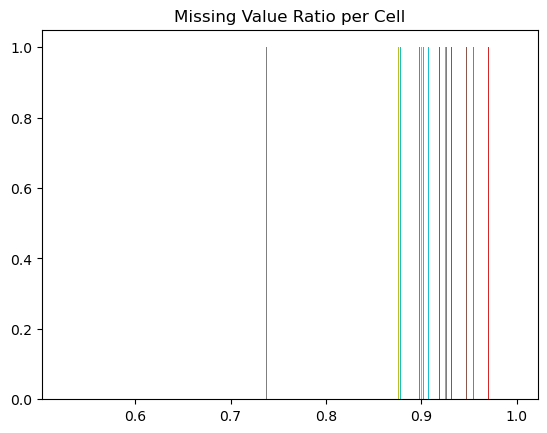

In [10]:
import matplotlib.pyplot as plt
no_call_ratio = (filtered_mtx == -1).mean(axis=0)
plt.hist(no_call_ratio, bins=30)
plt.title("Missing Value Ratio per Cell")

/Users/liqun/anaconda3/envs/singleCell/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


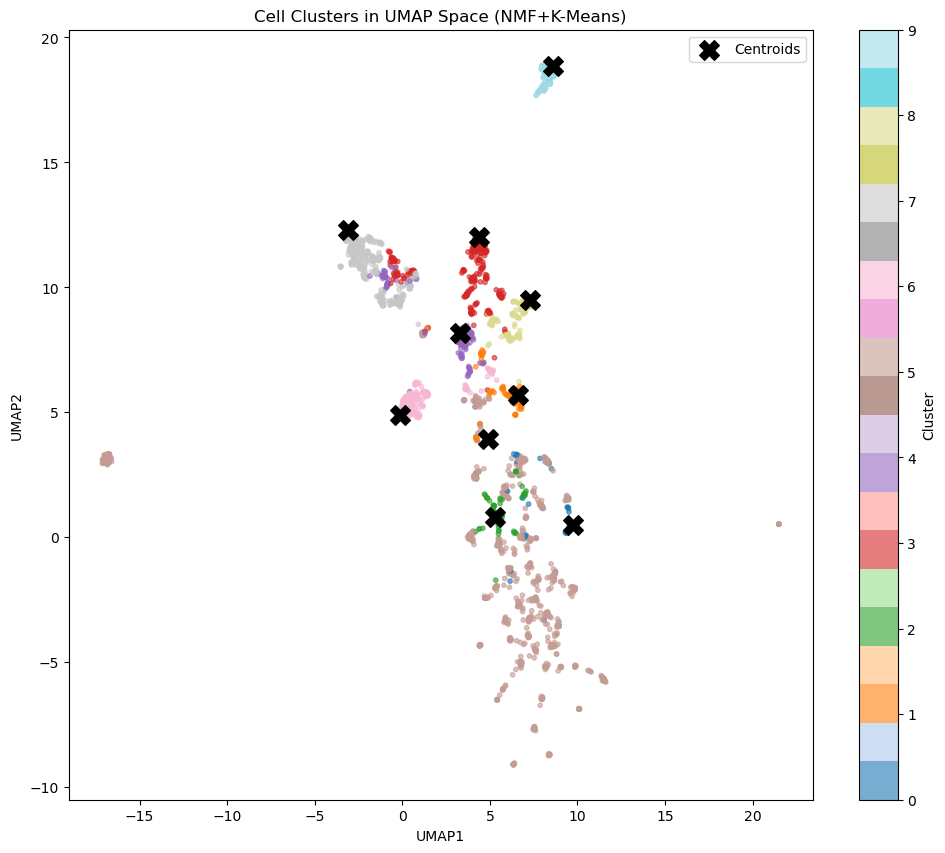

In [23]:
import numpy as np
import pandas as pd
from scipy import sparse
import matplotlib.pyplot as plt
from sklearn.decomposition import NMF
from sklearn.cluster import KMeans
import umap.umap_ as umap

# 转换为NMF可用的非负矩阵 (0/1/2)
nmf_input = filtered_mtx.copy().astype(np.float32)
nmf_input.data = nmf_input.data + 1  # -1→0, 0→1, 1→2

# NMF降维
n_components = 50  # 潜在特征数
nmf = NMF(n_components=n_components, 
          init='nndsvd', 
          random_state=42,
          max_iter=1000)
W = nmf.fit_transform(nmf_input.T)  # 细胞嵌入矩阵 [n_cells, n_components]
H = nmf.components_                # 突变特征矩阵 [n_components, n_mutations]

# K-Means聚类
kmeans = KMeans(n_clusters=10, random_state=42)
clusters = kmeans.fit_predict(W)

reducer = umap.UMAP(metric='cosine', random_state=42)
embedding = reducer.fit_transform(W)

plt.figure(figsize=(12, 10))
sc = plt.scatter(embedding[:, 0], embedding[:, 1],
                c=clusters, 
                s=10,
                cmap='tab20',
                alpha=0.6)
plt.colorbar(sc, label='Cluster')
plt.title("Cell Clusters in UMAP Space (NMF+K-Means)")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")

# 标记聚类中心
centers_umap = reducer.transform(kmeans.cluster_centers_)
plt.scatter(centers_umap[:, 0], centers_umap[:, 1],
           marker='X', s=200, c='black', label='Centroids')
plt.legend()
plt.show()

/Users/liqun/anaconda3/envs/singleCell/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


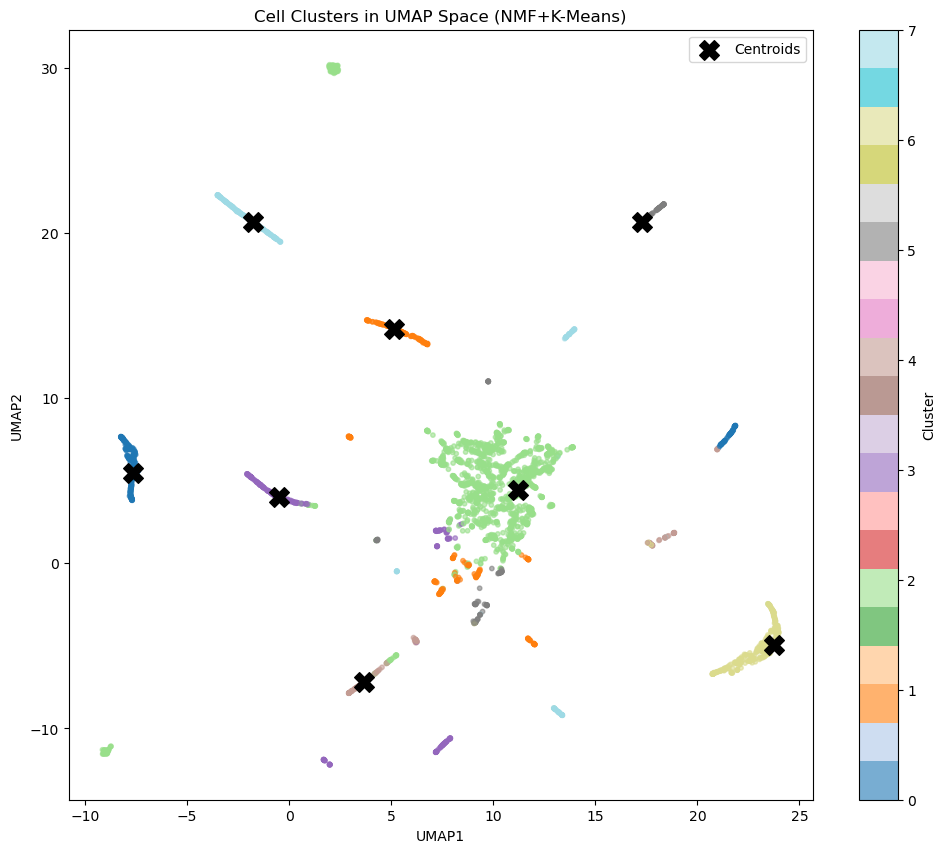

In [15]:
# UMAP降维
reducer = umap.UMAP(metric='cosine', random_state=42)
embedding = reducer.fit_transform(W)

plt.figure(figsize=(12, 10))
sc = plt.scatter(embedding[:, 0], embedding[:, 1],
                c=clusters, 
                s=10,
                cmap='tab20',
                alpha=0.6)
plt.colorbar(sc, label='Cluster')
plt.title("Cell Clusters in UMAP Space (NMF+K-Means)")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")

# 标记聚类中心
centers_umap = reducer.transform(kmeans.cluster_centers_)
plt.scatter(centers_umap[:, 0], centers_umap[:, 1],
           marker='X', s=200, c='black', label='Centroids')
plt.legend()
plt.show()

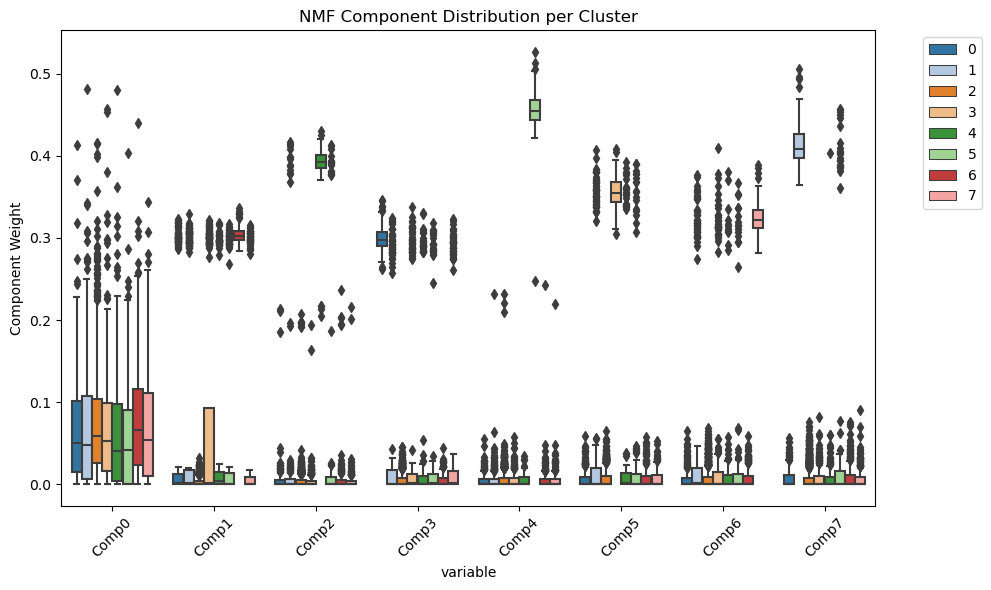

In [16]:
# 计算每个聚类在NMF组分上的平均权重
import seaborn as sns
cluster_components = pd.DataFrame(W, 
                                columns=[f"Comp{i}" for i in range(n_components)])
cluster_components['Cluster'] = clusters

plt.figure(figsize=(10, 6))
sns.boxplot(data=cluster_components.melt(id_vars='Cluster'),
            x='variable', y='value', hue='Cluster',
            palette='tab20')
plt.title("NMF Component Distribution per Cluster")
plt.xticks(rotation=45)
plt.ylabel("Component Weight")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

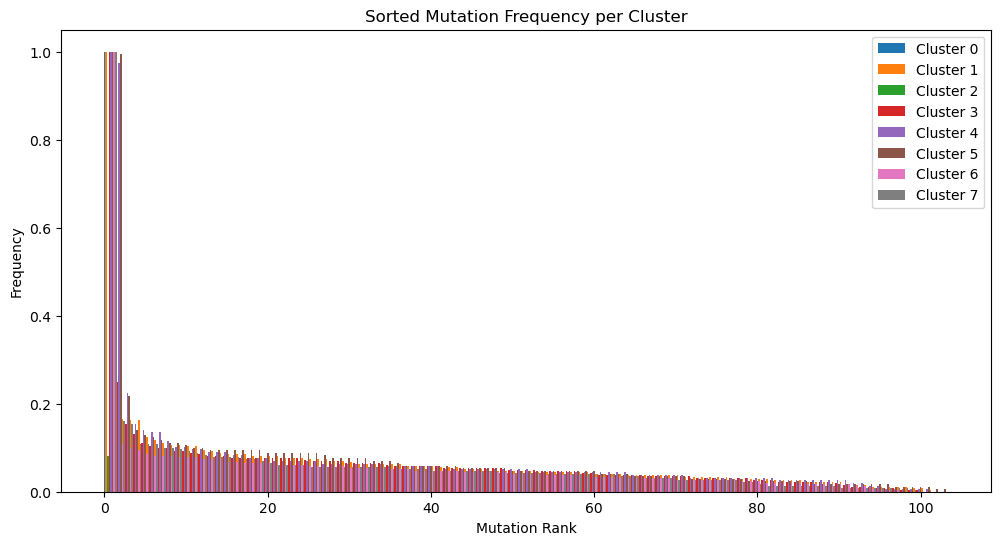

In [17]:
# 统计每个聚类的突变频率
cluster_mut_freq = []
for cl in np.unique(clusters):
    cells_in_cluster = (clusters == cl)
    freq = (filtered_mtx[:, cells_in_cluster] == 1).mean(axis=1).A1
    cluster_mut_freq.append(freq)

plt.figure(figsize=(12, 6))
for i, (cl, freqs) in enumerate(zip(np.unique(clusters), cluster_mut_freq)):
    plt.bar(np.arange(len(freqs)) + i*0.2, 
            np.sort(freqs)[::-1], 
            width=0.2, 
            label=f'Cluster {cl}')
plt.title("Sorted Mutation Frequency per Cluster")
plt.xlabel("Mutation Rank")
plt.ylabel("Frequency")
plt.legend()
plt.show()

/Users/liqun/anaconda3/envs/singleCell/lib/python3.10/site-packages/sklearn/decomposition/_nmf.py:1692: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(
/Users/liqun/anaconda3/envs/singleCell/lib/python3.10/site-packages/sklearn/decomposition/_nmf.py:1692: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(
/Users/liqun/anaconda3/envs/singleCell/lib/python3.10/site-packages/sklearn/decomposition/_nmf.py:1692: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


Text(0, 0.5, 'Error')

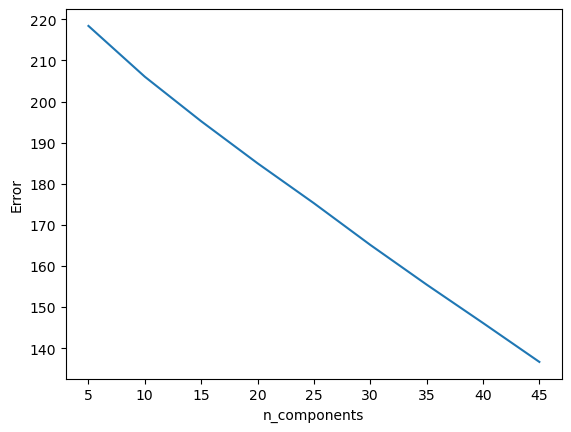

In [18]:
errors = []
for k in range(5, 50, 5):
    nmf = NMF(n_components=k, init='nndsvd')
    nmf.fit(nmf_input.T)
    errors.append(nmf.reconstruction_err_)
plt.plot(range(5, 50, 5), errors); plt.xlabel('n_components'); plt.ylabel('Error')

Text(0.5, 0, 'n_clusters')

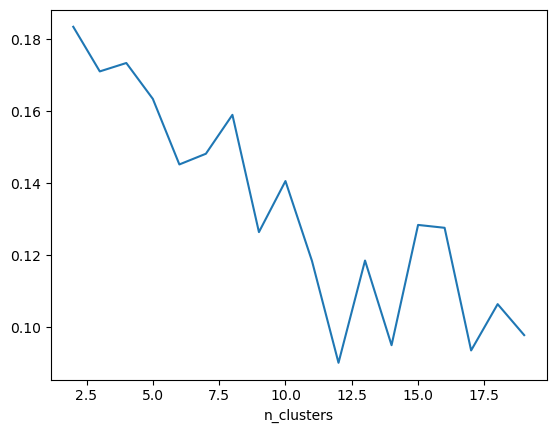

In [24]:
from sklearn.metrics import silhouette_score
scores = []
for k in range(2, 20):
    kmeans = KMeans(n_clusters=k)
    labels = kmeans.fit_predict(W)
    scores.append(silhouette_score(W, labels))
plt.plot(range(2, 20), scores); plt.xlabel('n_clusters')